# Implementación de un modelo de deep learning

## Alfredo Alejandro Soto Herrera - A01711368

### Configuración y carga de datos

In [ ]:
!pip -q install imagehash

In [ ]:
import os, sys, json, zipfile, shutil, hashlib, random, warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import imagehash
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

# Parámetros del proyecto
SEED = 42
IMG_SIZE = 224
RESIZE_MODE = "pad"
TRAIN_FOLDS, VAL_FOLDS, TEST_FOLDS = 14, 3, 3   # 70 % / 15 % / 15 %
PHASH_REMOVE_THR = 0
PHASH_GROUP_THR = 6

random.seed(SEED)
np.random.seed(SEED)

IN_COLAB = "google.colab" in sys.modules
WORK_DIR = "/content" if IN_COLAB else os.path.abspath("./work")
RAW_DIR = os.path.join(WORK_DIR, "raw")
PROC_DIR = os.path.join(WORK_DIR, "car_dataset_processed")
os.makedirs(WORK_DIR, exist_ok=True)
ZIP_PATH = "/content/drive/MyDrive/CarModel.zip"
print("Colab:", IN_COLAB, "| WORK_DIR:", WORK_DIR)

Colab: True | WORK_DIR: /content


In [ ]:
env_raw = os.environ.get("CAR_RAW_DIR")

if env_raw:
    RAW_DIR = env_raw
elif not os.path.isdir(RAW_DIR) or not os.listdir(RAW_DIR):
    if IN_COLAB:
        from google.colab import drive
        drive.mount("/content/drive")
        if not os.path.exists(ZIP_PATH):
            from google.colab import files
            up = files.upload()
            ZIP_PATH = list(up.keys())[0]
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(RAW_DIR)

for root, _, files_ in os.walk(RAW_DIR):
    if "metadata.csv" in files_:
        DATA_ROOT = root
        break
print("DATA_ROOT:", DATA_ROOT)
print(sorted(d for d in os.listdir(DATA_ROOT) if os.path.isdir(os.path.join(DATA_ROOT, d))))

Mounted at /content/drive
DATA_ROOT: /content/raw
['Audi_R8', 'Audi_RS5', 'BMW_M3', 'BMW_M5', 'Chevrolet_Camaro', 'Ford_Mustang', 'Mercedes_AMG_GT', 'Nissan_GT_R', 'Porsche_911', 'Toyota_Supra']


### EDA inicial

In [ ]:
meta = pd.read_csv(os.path.join(DATA_ROOT, "metadata.csv"))
print("Filas y columnas:", meta.shape)
display(meta.head())
print("\nValores nulos por columna:")
display(meta.isna().sum().to_frame("nulos").T)

Filas y columnas: (2084, 9)


,class,filename,title,creator,license,license_version,source,foreign_landing_url,original_url
0,BMW_M3,0000.jpg,BMW M3 E46 + E34,raito.akehanareru,by-sa,2.0,flickr,https://www.flickr.com/photos/109740338@N03/15...,https://live.staticflickr.com/7567/15621402140...
1,BMW_M3,0001.jpg,2001 BMW M3,The Pug Father,by,2.0,flickr,https://www.flickr.com/photos/76929828@N00/250...,https://live.staticflickr.com/3106/2504408734_...
2,BMW_M3,0002.jpg,BMW M3 E46,raito.akehanareru,by-sa,2.0,flickr,https://www.flickr.com/photos/109740338@N03/15...,https://live.staticflickr.com/5608/15804362901...
3,BMW_M3,0003.jpg,BMW M3 E46,raito.akehanareru,by-sa,2.0,flickr,https://www.flickr.com/photos/109740338@N03/15...,https://live.staticflickr.com/8578/15620427719...
4,BMW_M3,0004.jpg,BMW M3 E46,raito.akehanareru,by-sa,2.0,flickr,https://www.flickr.com/photos/109740338@N03/15...,https://live.staticflickr.com/7495/15806254535...



Valores nulos por columna:


,class,filename,title,creator,license,license_version,source,foreign_landing_url,original_url
nulos,0,0,0,0,0,0,0,0,0


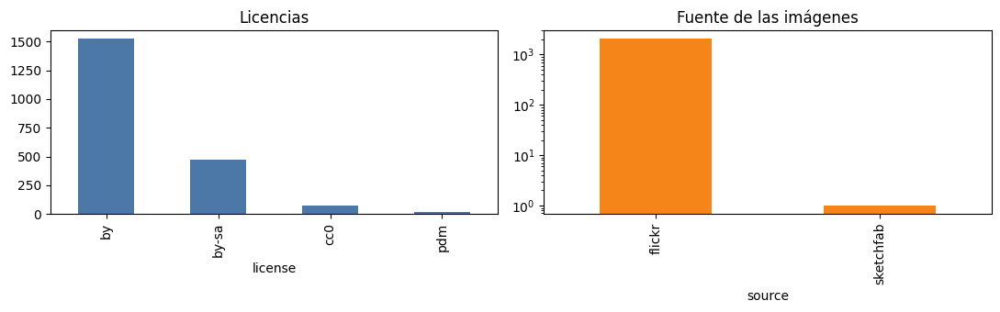

Fotógrafos/autores más frecuentes:


,imágenes
creator,
nakhon100,376
Prior Design NA (priordesignusa.com),135
Jacob Frey 4A,91
TheCarSpy,74
Falcon_33,74
crash71100,60
dave_7,53
Alexandre Prevot,46


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
meta["license"].value_counts().plot.bar(ax=ax[0], color="#4C78A8", title="Licencias")
meta["source"].value_counts().plot.bar(ax=ax[1], color="#F58518", title="Fuente de las imágenes", logy=True)
plt.tight_layout(); plt.show()

print("Fotógrafos/autores más frecuentes:")
display(meta["creator"].value_counts().head(8).to_frame("imágenes"))

El dataset trae atribución de cada foto. Casi todas vienen de Flickr, lo que significa que son fotos reales.


In [ ]:
def inspect_image(path):
    info = {"path": path}
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            info.update(width=im.width, height=im.height, mode=im.mode, format=im.format)
            rgb = im.convert("RGB")
            info["phash"] = str(imagehash.phash(rgb))
            arr = np.asarray(rgb.resize((64, 64)), dtype=float)
            info["brightness"] = arr.mean()
            small = np.asarray(rgb.resize((96, 96)), dtype=float)
            info["white_frac"] = (small.min(axis=2) > 225).mean()
        with open(path, "rb") as f:
            info["md5"] = hashlib.md5(f.read()).hexdigest()
        info["size_kb"] = os.path.getsize(path) / 1024
        info["error"] = None
    except Exception as e:
        info["error"] = str(e)
    return info

classes = sorted(d for d in os.listdir(DATA_ROOT) if os.path.isdir(os.path.join(DATA_ROOT, d)))
records = []
for c in classes:
    for f in sorted(os.listdir(os.path.join(DATA_ROOT, c))):
        r = inspect_image(os.path.join(DATA_ROOT, c, f))
        r["class"], r["filename"] = c, f
        records.append(r)

inv = pd.DataFrame(records)
inv["aspect"] = inv["width"] / inv["height"]
inv = inv.merge(meta[["class", "filename", "source", "creator", "license"]], on=["class", "filename"], how="left")
print("Total de imágenes en disco:", len(inv))
print("Imágenes con error al abrir:", inv["error"].notna().sum())
print("Coinciden con metadata.csv:", inv["source"].notna().sum(), "de", len(inv))
display(inv.drop(columns=["path"]).head())

Total de imágenes en disco: 2084
Imágenes con error al abrir: 0
Coinciden con metadata.csv: 2084 de 2084


,width,height,mode,format,phash,brightness,white_frac,md5,size_kb,error,class,filename,aspect,source,creator,license
0,1024,681,RGB,JPEG,95a4e143db6db432,83.483480,0.002387,d26582a0b683e2481724b6660074ab47,227.267578,None,Audi_R8,0000.jpg,1.503671,flickr,leunix,by-sa
1,1024,712,RGB,JPEG,cab2d8cda2631d5c,142.142822,0.163411,d7583b5b93ce160b1731a4f5955c1320,178.180664,None,Audi_R8,0001.jpg,1.438202,flickr,MeistrJam,by
2,1024,683,RGB,JPEG,cc3d2be798ea1c88,50.107422,0.000434,5f0d6a33baf2c37b4761c7d5f145bc07,169.120117,None,Audi_R8,0002.jpg,1.499268,flickr,Prior Design NA (priordesignusa.com),by
3,1024,768,RGB,JPEG,d1e82e8793786c87,18.203776,0.001194,380d2e597e2ab5b9eb4cbc7318fd9cdd,106.051758,None,Audi_R8,0003.jpg,1.333333,flickr,Michi1308,by-sa
4,333,499,RGB,JPEG,d84d3562c39732ec,74.798258,0.004123,2bff17eb3ffa2a8c580fc7f38d16c01e,56.573242,None,Audi_R8,0004.jpg,0.667335,flickr,Prior Design NA (priordesignusa.com),by


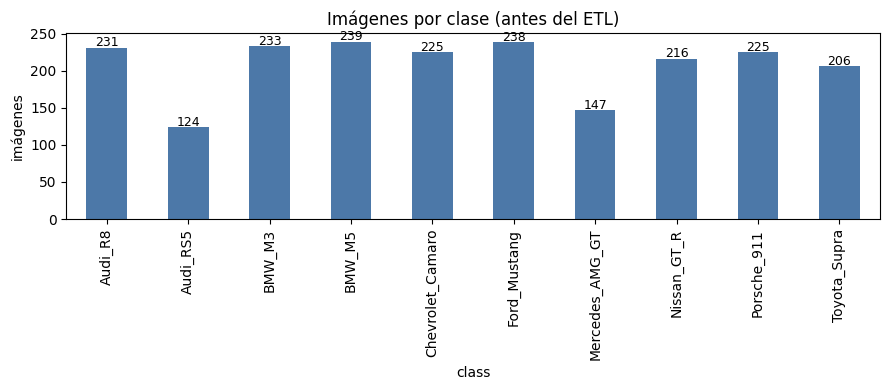

Clase más grande: BMW_M5 (239)  |  clase más pequeña: Audi_RS5 (124)
Razón de desbalance (máx/mín): 1.93


In [ ]:
counts = inv["class"].value_counts().sort_index()
ax = counts.plot.bar(figsize=(9, 4), color="#4C78A8", title="Imágenes por clase (antes del ETL)")
for i, v in enumerate(counts.values):
    ax.text(i, v + 2, str(v), ha="center", fontsize=9)
plt.ylabel("imágenes"); plt.tight_layout(); plt.show()

print(f"Clase más grande: {counts.idxmax()} ({counts.max()})  |  clase más pequeña: {counts.idxmin()} ({counts.min()})")
print(f"Razón de desbalance (máx/mín): {counts.max()/counts.min():.2f}")

Algunas clases tienen menos fotos que otras.

In [ ]:
print("Formatos:", inv["format"].value_counts().to_dict())
print("Modos de color:", inv["mode"].value_counts().to_dict())
display(inv[["width", "height", "aspect", "size_kb", "brightness"]].describe().round(2))

Formatos: {'JPEG': 2084}
Modos de color: {'RGB': 2084}


,width,height,aspect,size_kb,brightness
count,2084.00,2084.00,2084.00,2084.00,2084.00
mean,997.24,705.24,1.44,185.34,107.40
std,108.25,114.03,0.23,63.51,30.57
min,320.00,303.00,0.56,12.22,9.30
25%,1024.00,667.00,1.33,141.44,89.07
50%,1024.00,685.00,1.48,186.36,109.14
75%,1024.00,768.00,1.51,228.04,126.23
max,1920.00,1080.00,3.37,368.44,245.73


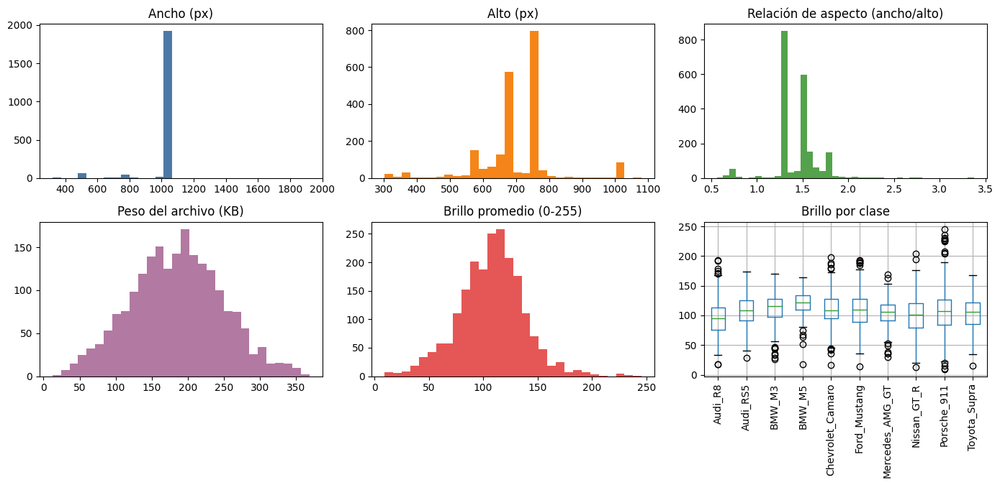

Resoluciones más comunes:


imágenes
width height          
1024  768          771
      683          288
      576           86
      640           73
      681           37
1023  685           32

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
ax = ax.ravel()
ax[0].hist(inv["width"], bins=30, color="#4C78A8");  ax[0].set_title("Ancho (px)")
ax[1].hist(inv["height"], bins=30, color="#F58518"); ax[1].set_title("Alto (px)")
ax[2].hist(inv["aspect"], bins=40, color="#54A24B"); ax[2].set_title("Relación de aspecto (ancho/alto)")
ax[3].hist(inv["size_kb"], bins=30, color="#B279A2"); ax[3].set_title("Peso del archivo (KB)")
ax[4].hist(inv["brightness"], bins=30, color="#E45756"); ax[4].set_title("Brillo promedio (0-255)")
inv.boxplot(column="brightness", by="class", ax=ax[5], rot=90)
ax[5].set_title("Brillo por clase"); ax[5].set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()

print("Resoluciones más comunes:")
display(inv.groupby(["width", "height"]).size().sort_values(ascending=False).head(6).to_frame("imágenes"))

No tienen el mismo tamaño ni la misma proporción, así que habrá que reescalarlas en el ETL.

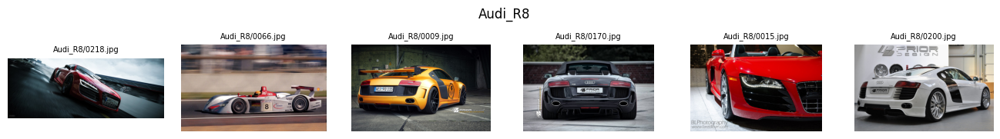

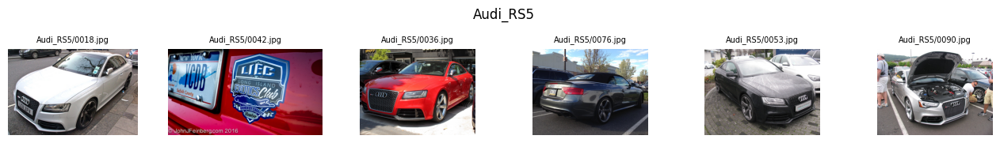

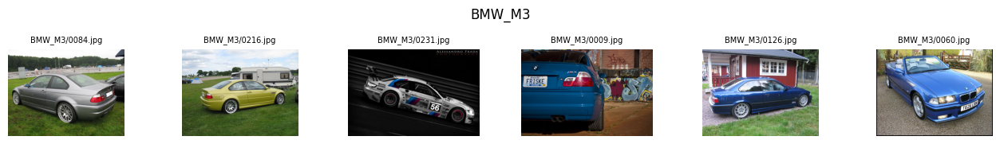

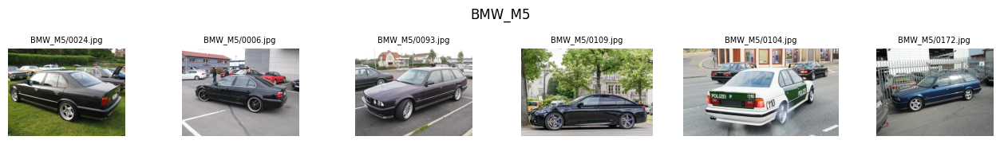

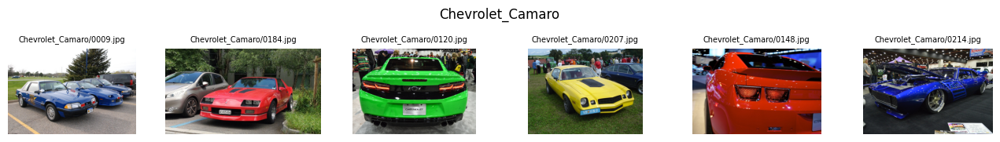

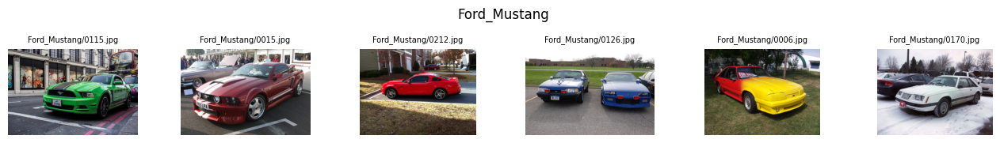

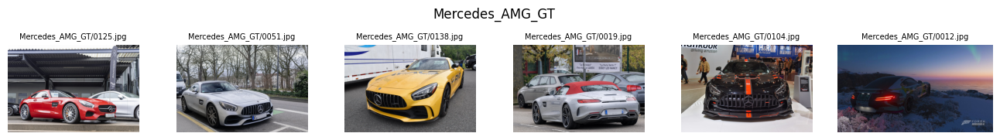

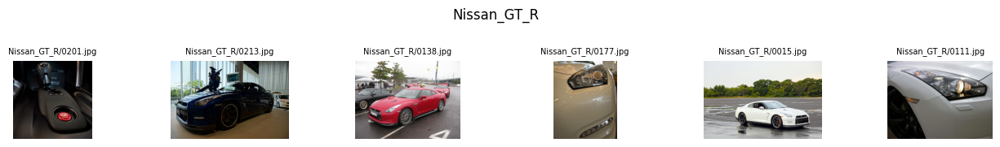

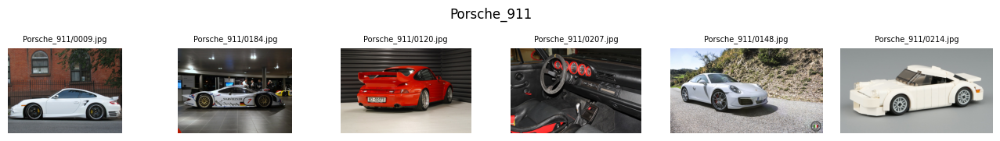

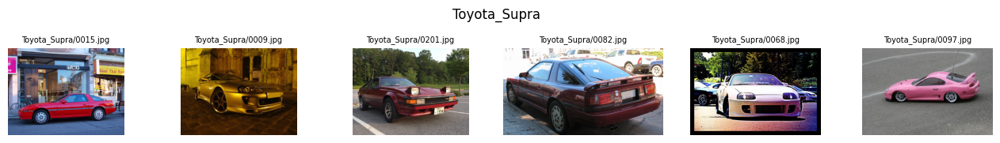

In [ ]:
def show_grid(df, ncols=6, size=2.2, title=None, annotate=None):
    n = len(df)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 0.8))
    axes = np.atleast_1d(axes).ravel()
    for a in axes:
        a.axis("off")
    for a, (_, r) in zip(axes, df.iterrows()):
        a.imshow(Image.open(r["path"]).convert("RGB"))
        label = f"{r['class']}/{r['filename']}"
        if annotate:
            label += f"\n{annotate(r)}"
        a.set_title(label, fontsize=7)
    if title:
        plt.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()

for c in classes:
    sample = inv[inv["class"] == c].sample(6, random_state=SEED)
    show_grid(sample, title=c)

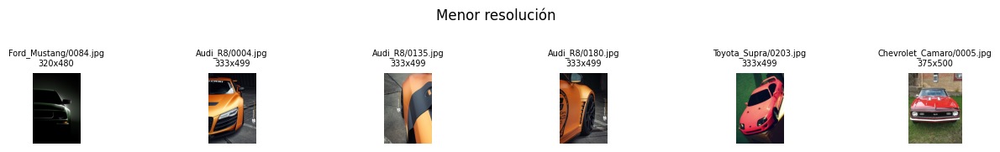

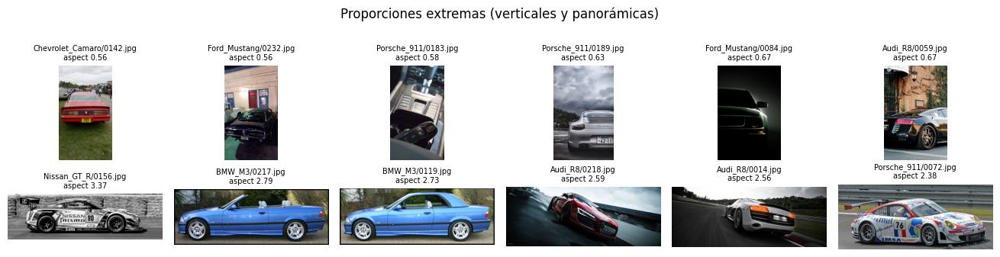

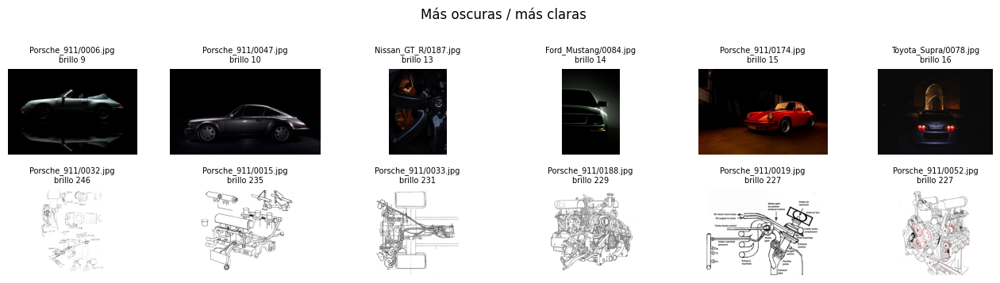

In [ ]:
small = inv.nsmallest(6, "width")
tall = inv.nsmallest(6, "aspect")
wide = inv.nlargest(6, "aspect")
dark = inv.nsmallest(6, "brightness")
bright = inv.nlargest(6, "brightness")

show_grid(small, title="Menor resolución", annotate=lambda r: f"{r['width']}x{r['height']}")
show_grid(pd.concat([tall, wide]), title="Proporciones extremas (verticales y panorámicas)", annotate=lambda r: f"aspect {r['aspect']:.2f}")
show_grid(pd.concat([dark, bright]), title="Más oscuras / más claras", annotate=lambda r: f"brillo {r['brightness']:.0f}")

Con esta prueba se detectaron imágenes que no son de autos, sino diagramas de motor u otras cosas, esto sugiere que el dataset puede traer más basura.

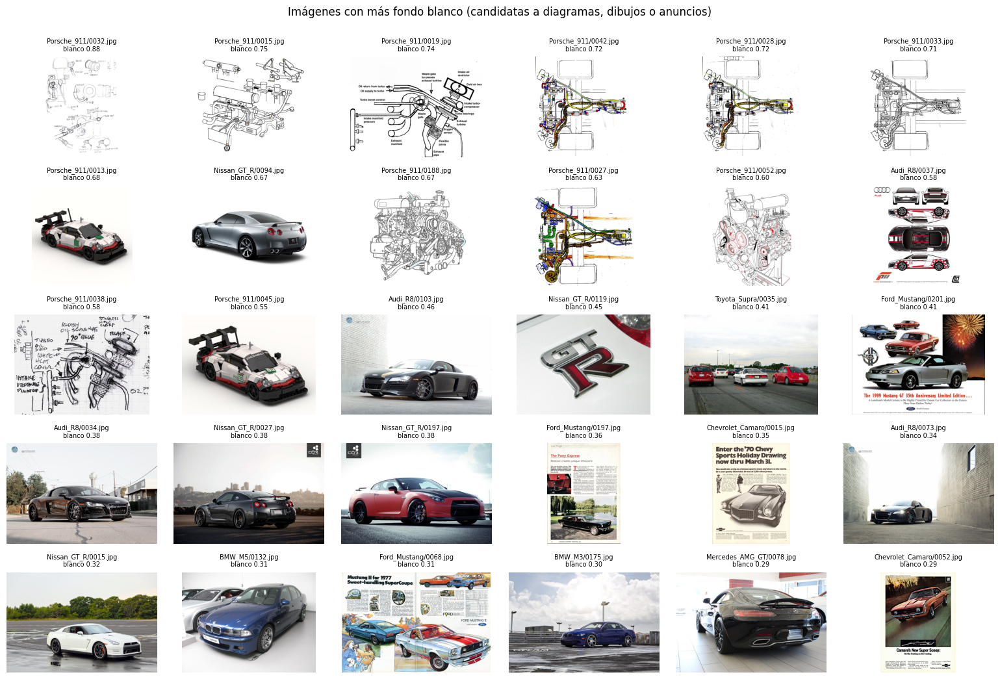

In [ ]:
cand = inv.sort_values("white_frac", ascending=False).head(30)
show_grid(cand, ncols=6, size=2.6, title="Imágenes con más fondo blanco (candidatas a diagramas, dibujos o anuncios)",
          annotate=lambda r: f"blanco {r['white_frac']:.2f}")

Con esta prueba nos dimos cuenta que hay más fotos así que es evidente que no sirven para el modelo, esto levanta la sospecha de que pueda haber más y es necesario revisarlas con calma.


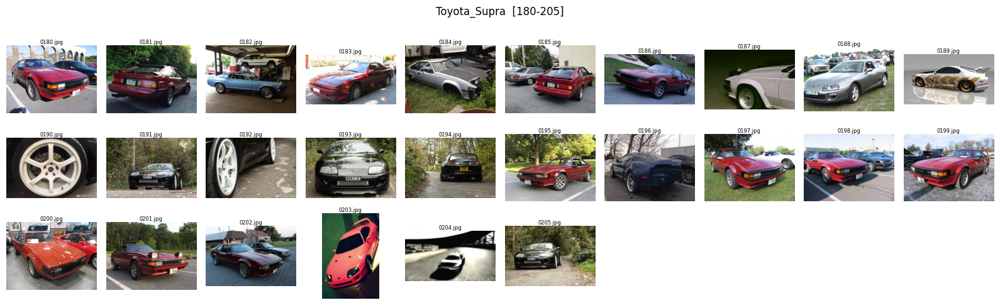

In [59]:
def contact_sheet(cls, start=0, n=60, ncols=10, size=1.6):
    sub = inv[inv["class"] == cls].iloc[start:start + n]
    nrows = int(np.ceil(len(sub) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    axes = np.atleast_1d(axes).ravel()
    for a in axes:
        a.axis("off")
    for a, (_, r) in zip(axes, sub.iterrows()):
        im = Image.open(r["path"]).convert("RGB")
        im.thumbnail((160, 160))
        a.imshow(im); a.set_title(r["filename"], fontsize=6, pad=1)
    plt.suptitle(f"{cls}  [{start}-{start + len(sub) - 1}]", y=1.0)
    plt.tight_layout(); plt.show()

contact_sheet("Toyota_Supra", start=180)

In [ ]:
bits = np.array([[int(b) for b in format(int(h, 16), "064b")] for h in inv["phash"]], dtype=np.float32)
dist = 64 - (bits @ bits.T + (1 - bits) @ (1 - bits).T)
np.fill_diagonal(dist, 99)
dist = dist.astype(int)

ii, jj = np.where(np.triu(dist <= PHASH_GROUP_THR))
pairs = pd.DataFrame({"i": ii, "j": jj, "dist": dist[ii, jj]})
pairs["class_i"] = inv["class"].values[ii];  pairs["file_i"] = inv["filename"].values[ii]
pairs["class_j"] = inv["class"].values[jj];  pairs["file_j"] = inv["filename"].values[jj]
pairs["misma_clase"] = pairs["class_i"] == pairs["class_j"]

print("Duplicados exactos (MD5):", inv["md5"].duplicated().sum())
print("Pares con pHash <= %d:" % PHASH_GROUP_THR, len(pairs))
print("   de ellos entre CLASES DISTINTAS (etiquetas en conflicto):", (~pairs["misma_clase"]).sum())
display(pairs.drop(columns=["i", "j"]).sort_values("dist"))

Duplicados exactos (MD5): 9
Pares con pHash <= 6: 14
   de ellos entre CLASES DISTINTAS (etiquetas en conflicto): 6


,dist,class_i,file_i,class_j,file_j,misma_clase
0,0,Audi_R8,0061.jpg,Audi_R8,0221.jpg,True
1,0,Audi_RS5,0025.jpg,Audi_RS5,0029.jpg,True
2,0,Audi_RS5,0028.jpg,Audi_RS5,0035.jpg,True
3,0,BMW_M3,0080.jpg,BMW_M5,0156.jpg,False
4,0,Chevrolet_Camaro,0002.jpg,Ford_Mustang,0009.jpg,False
5,0,Chevrolet_Camaro,0009.jpg,Ford_Mustang,0030.jpg,False
6,0,Chevrolet_Camaro,0020.jpg,Ford_Mustang,0069.jpg,False
7,0,Chevrolet_Camaro,0021.jpg,Ford_Mustang,0074.jpg,False
8,0,Chevrolet_Camaro,0040.jpg,Ford_Mustang,0126.jpg,False
9,0,Chevrolet_Camaro,0171.jpg,Chevrolet_Camaro,0203.jpg,True


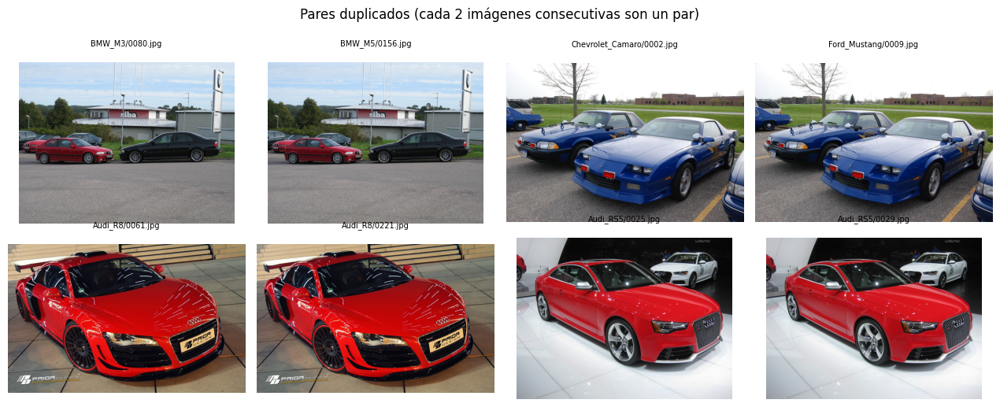

In [ ]:
ejemplos = []
cross = pairs[~pairs["misma_clase"]].head(2)
same = pairs[pairs["misma_clase"]].head(2)
for _, p in pd.concat([cross, same]).iterrows():
    ejemplos += [inv.iloc[p["i"]], inv.iloc[p["j"]]]
show_grid(pd.DataFrame(ejemplos), ncols=4, size=3.2, title="Pares duplicados (cada 2 imágenes consecutivas son un par)",
          annotate=lambda r: "")

Hay fotos exactamente repetidas que se eliminarán en el ETL.

En metadata pero no en disco: 0
En disco pero no en metadata: 0

Imágenes cuya fuente NO es Flickr:


,class,filename,source,creator
354,Audi_RS5,0123.jpg,sketchfab,Indians


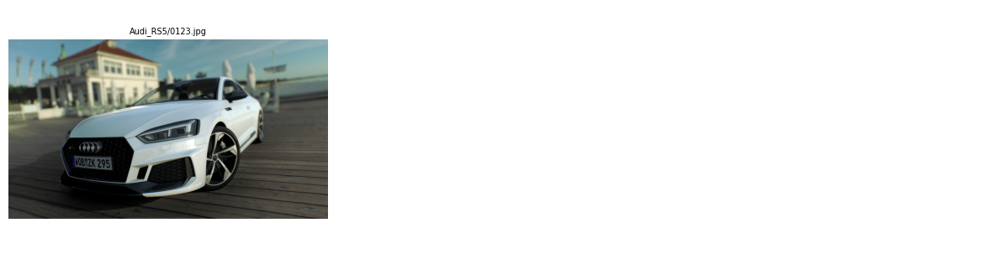

In [ ]:
meta_set = set(zip(meta["class"], meta["filename"]))
disk_set = set(zip(inv["class"], inv["filename"]))
print("En metadata pero no en disco:", len(meta_set - disk_set))
print("En disco pero no en metadata:", len(disk_set - meta_set))
print("\nImágenes cuya fuente NO es Flickr:")
display(inv[inv["source"] != "flickr"][["class", "filename", "source", "creator"]])
if (inv["source"] != "flickr").any():
    show_grid(inv[inv["source"] != "flickr"], ncols=3, size=4)

Conclusiones:
- Hay 2,084 imágenes JPEG/RGB en 10 clases, ninguna corrupta.
- Las clases están algo desbalanceadas.
- Los tamaños y proporciones son heterogéneos, así que hay que unificarlos sin deformar el auto.
- Existen duplicados exactos, algunos con etiquetas contradictorias entre clases.
- Una imagen viene de Sketchfab y varias más no son fotos de un auto.
- Algunas fotos muestran 2 autos a la vez.

### ETL

In [60]:
etl_log = []
df = inv.copy()
n0 = len(df)

# 1) Archivos corruptos
bad = df["error"].notna()
etl_log.append(("Archivos corruptos", int(bad.sum())))
df = df[~bad].copy()

# 2) No son fotografías reales
not_photo = df["source"] != "flickr"
etl_log.append(("No son fotos reales (fuente ≠ Flickr)", int(not_photo.sum())))
df = df[~not_photo].copy().reset_index(drop=True)
print("Quedan:", len(df))

Quedan: 2083


In [61]:
# 3) Duplicados
def pairwise_phash_dist(frame):
    b = np.array([[int(x) for x in format(int(h, 16), "064b")] for h in frame["phash"]], dtype=np.float32)
    d = 64 - (b @ b.T + (1 - b) @ (1 - b).T)
    np.fill_diagonal(d, 99)
    return d.astype(int)

class UnionFind:
    def __init__(self, n): self.p = list(range(n))
    def find(self, x):
        while self.p[x] != x:
            self.p[x] = self.p[self.p[x]]; x = self.p[x]
        return x
    def union(self, a, b): self.p[self.find(a)] = self.find(b)

def groups_from_threshold(frame, thr):
    d = pairwise_phash_dist(frame)
    uf = UnionFind(len(frame))
    ii, jj = np.where(np.triu(d <= thr))
    for a, b in zip(ii, jj):
        uf.union(a, b)
    return np.array([uf.find(i) for i in range(len(frame))])

df["dup_group"] = groups_from_threshold(df, PHASH_REMOVE_THR)
drop_idx = []
cross_removed, same_removed = 0, 0
for g, sub in df.groupby("dup_group"):
    if len(sub) == 1:
        continue
    if sub["class"].nunique() > 1:
        drop_idx += list(sub.index); cross_removed += len(sub)
    else:
        drop_idx += list(sub.index[1:]); same_removed += len(sub) - 1

etl_log.append(("Duplicados dentro de la misma clase (se conserva 1)", same_removed))
etl_log.append(("Duplicados entre clases distintas (se eliminan todas las copias)", cross_removed))
df = df.drop(index=drop_idx).reset_index(drop=True)
print("Quedan:", len(df))

Quedan: 2067


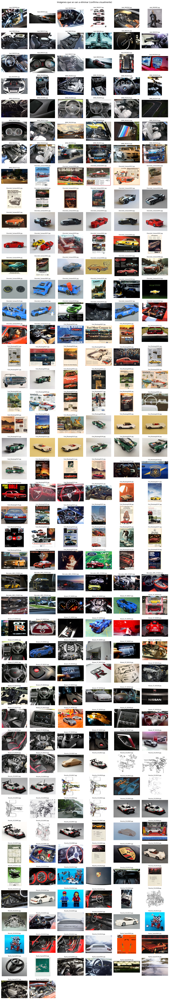

Quedan: 1807


In [62]:
# 4) Imágenes que no son un auto real
REMOVE_MANUAL = [
    # Diagramas, bocetos y dibujos técnicos de motor
    ("Porsche_911", "0001.jpg"), ("Porsche_911", "0015.jpg"), ("Porsche_911", "0019.jpg"), ("Porsche_911", "0027.jpg"),
    ("Porsche_911", "0028.jpg"), ("Porsche_911", "0032.jpg"), ("Porsche_911", "0033.jpg"), ("Porsche_911", "0038.jpg"),
    ("Porsche_911", "0042.jpg"), ("Porsche_911", "0052.jpg"), ("Porsche_911", "0065.jpg"), ("Porsche_911", "0188.jpg"),
    # Modelos LEGO/juguetes
    ("Porsche_911", "0013.jpg"), ("Porsche_911", "0023.jpg"), ("Porsche_911", "0024.jpg"), ("Porsche_911", "0045.jpg"),
    ("Porsche_911", "0043.jpg"), ("Porsche_911", "0044.jpg"), ("Porsche_911", "0045.jpg"), ("Porsche_911", "0057.jpg"),
    ("Porsche_911", "0068.jpg"), ("Porsche_911", "0102.jpg"), ("Porsche_911", "0123.jpg"), ("Porsche_911", "0160.jpg"),
    ("Porsche_911", "0162.jpg"), ("Porsche_911", "0214.jpg"), ("Porsche_911", "0215.jpg"), ("Porsche_911", "0218.jpg"),
    ("BMW_M5", "0055.jpg"), ("BMW_M5", "0131.jpg"), ("BMW_M5", "0160.jpg"), ("Chevrolet_Camaro", "0025.jpg"),
    ("Chevrolet_Camaro", "0026.jpg"), ("Chevrolet_Camaro", "0031.jpg"), ("Chevrolet_Camaro", "0032.jpg"),
    ("Chevrolet_Camaro", "0033.jpg"), ("Chevrolet_Camaro", "0034.jpg"), ("Chevrolet_Camaro", "0035.jpg"),
    ("Chevrolet_Camaro", "0036.jpg"), ("Chevrolet_Camaro", "0037.jpg"), ("Chevrolet_Camaro", "0056.jpg"),
    ("Chevrolet_Camaro", "0086.jpg"), ("Chevrolet_Camaro", "0087.jpg"), ("Chevrolet_Camaro", "0101.jpg"),
    ("Chevrolet_Camaro", "0125.jpg"), ("Chevrolet_Camaro", "0127.jpg"), ("Chevrolet_Camaro", "0167.jpg"),
    ("Ford_Mustang", "0050.jpg"), ("Ford_Mustang", "0098.jpg"), ("Ford_Mustang", "0099.jpg"), ("Ford_Mustang", "0100.jpg"),
    ("Ford_Mustang", "0101.jpg"), ("Ford_Mustang", "0102.jpg"), ("Ford_Mustang", "0103.jpg"), ("Ford_Mustang", "0104.jpg"),
    ("Ford_Mustang", "0105.jpg"), ("Ford_Mustang", "0106.jpg"), ("Ford_Mustang", "0107.jpg"), ("Nissan_GT_R", "0017.jpg"),
    ("Nissan_GT_R", "0019.jpg"), ("Nissan_GT_R", "0049.jpg"), ("Nissan_GT_R", "0064.jpg"), ("Nissan_GT_R", "0095.jpg"),
    ("Nissan_GT_R", "0181.jpg"), ("Nissan_GT_R", "0208.jpg"),
    # Interior
    ("Porsche_911", "0081.jpg"), ("Porsche_911", "0085.jpg"), ("Porsche_911", "0118.jpg"), ("Porsche_911", "0183.jpg"),
    ("Porsche_911", "0129.jpg"), ("Porsche_911", "0163.jpg"), ("Porsche_911", "0183.jpg"), ("Porsche_911", "0201.jpg"),
    ("Porsche_911", "0207.jpg"), ("Porsche_911", "0219.jpg"), ("Porsche_911", "0221.jpg"), ("Audi_R8", "0008.jpg"),
    ("Audi_R8", "0023.jpg"), ("Audi_R8", "0040.jpg"), ("Audi_R8", "0136.jpg"), ("Audi_R8", "0137.jpg"),
    ("Audi_R8", "0138.jpg"), ("Audi_R8", "0189.jpg"), ("Audi_R8", "0191.jpg"), ("Audi_R8", "0193.jpg"),
    ("Audi_R8", "0202.jpg"), ("Audi_R8", "0215.jpg"), ("Audi_R8", "0217.jpg"), ("Audi_RS5", "0013.jpg"),
    ("Audi_RS5", "0045.jpg"), ("BMW_M3", "0008.jpg"), ("BMW_M3", "0014.jpg"), ("BMW_M3", "0015.jpg"), ("BMW_M3", "0016.jpg"),
    ("BMW_M3", "0020.jpg"), ("BMW_M3", "0028.jpg"), ("BMW_M3", "0094.jpg"), ("BMW_M3", "0099.jpg"), ("BMW_M3", "0129.jpg"),
    ("BMW_M3", "0170.jpg"), ("BMW_M3", "0174.jpg"), ("BMW_M3", "0208.jpg"), ("BMW_M3", "0219.jpg"), ("BMW_M3", "0224.jpg"),
    ("BMW_M3", "0229.jpg"), ("Chevrolet_Camaro", "0039.jpg"), ("Chevrolet_Camaro", "0108.jpg"),
    ("Chevrolet_Camaro", "0131.jpg"), ("Chevrolet_Camaro", "169.jpg"), ("Chevrolet_Camaro", "0187.jpg"),
    ("Chevrolet_Camaro", "0222.jpg"), ("Ford_Mustang", "0085.jpg"), ("Ford_Mustang", "0127.jpg"),
    ("Ford_Mustang", "0150.jpg"), ("Ford_Mustang", "0151.jpg"), ("Ford_Mustang", "0161.jpg"), ("Ford_Mustang", "0181.jpg"),
    ("Mercedes_AMG_GT", "0092.jpg"), ("Mercedes_AMG_GT", "0097.jpg"), ("Nissan_GT_R", "0002.jpg"),
    ("Nissan_GT_R", "0003.jpg"), ("Nissan_GT_R", "0035.jpg"), ("Nissan_GT_R", "0045.jpg"), ("Nissan_GT_R", "0061.jpg"),
    ("Nissan_GT_R", "0089.jpg"), ("Nissan_GT_R", "0093.jpg"), ("Nissan_GT_R", "0097.jpg"), ("Nissan_GT_R", "0101.jpg"),
    ("Nissan_GT_R", "0108.jpg"), ("Nissan_GT_R", "0126.jpg"), ("Nissan_GT_R", "0128.jpg"), ("Nissan_GT_R", "0140.jpg"),
    ("Nissan_GT_R", "0154.jpg"), ("Nissan_GT_R", "0167.jpg"), ("Nissan_GT_R", "0175.jpg"), ("Nissan_GT_R", "0176.jpg"),
    ("Nissan_GT_R", "0188.jpg"), ("Nissan_GT_R", "0189.jpg"), ("Nissan_GT_R", "0198.jpg"), ("Nissan_GT_R", "0199.jpg"),
    ("Nissan_GT_R", "0200.jpg"), ("Nissan_GT_R", "0201.jpg"), ("Nissan_GT_R", "0207.jpg"), ("Nissan_GT_R", "0209.jpg"),
    ("Nissan_GT_R", "0210.jpg"), ("Toyota_Supra", "0091.jpg"), ("Toyota_Supra", "0092.jpg"),
    ("Toyota_Supra", "0157.jpg"), ("Toyota_Supra", "0170.jpg"),
    # Plantilla de decoración
    ("Audi_R8", "0037.jpg"), ("Audi_RS5", "0042.jpg"), ("Chevrolet_Camaro", "0066.jpg"), ("Chevrolet_Camaro", "0124.jpg"),
    ("Ford_Mustang", "0047.jpg"), ("Nissan_GT_R", "0119.jpg"), ("Nissan_GT_R", "0124.jpg"),
    # Anuncios y páginas de revista
    ("Porsche_911", "0031.jpg"), ("Porsche_911", "0062.jpg"), ("Porsche_911", "0074.jpg"), ("Porsche_911", "0092.jpg"),
    ("Porsche_911", "0118.jpg"), ("Porsche_911", "0111.jpg"), ("Porsche_911", "0130.jpg"), ("Porsche_911", "0131.jpg"),
    ("Audi_R8", "0082.jpg"), ("Chevrolet_Camaro", "0000.jpg"), ("Chevrolet_Camaro", "0006.jpg"),
    ("Chevrolet_Camaro", "0007.jpg"), ("Chevrolet_Camaro", "0012.jpg"), ("Chevrolet_Camaro", "0014.jpg"),
    ("Chevrolet_Camaro", "0015.jpg"), ("Chevrolet_Camaro", "0016.jpg"), ("Chevrolet_Camaro", "0019.jpg"),
    ("Chevrolet_Camaro", "0022.jpg"), ("Chevrolet_Camaro", "0027.jpg"), ("Chevrolet_Camaro", "0041.jpg"),
    ("Chevrolet_Camaro", "0043.jpg"), ("Chevrolet_Camaro", "0045.jpg"), ("Chevrolet_Camaro", "0049.jpg"),
    ("Chevrolet_Camaro", "0052.jpg"), ("Chevrolet_Camaro", "0073.jpg"), ("Chevrolet_Camaro", "0084.jpg"),
    ("Chevrolet_Camaro", "0105.jpg"), ("Chevrolet_Camaro", "0128.jpg"), ("Ford_Mustang", "0003.jpg"),
    ("Ford_Mustang", "0007.jpg"), ("Ford_Mustang", "0010.jpg"), ("Ford_Mustang", "0021.jpg"), ("Ford_Mustang", "0027.jpg"),
    ("Ford_Mustang", "0036.jpg"), ("Ford_Mustang", "0037.jpg"), ("Ford_Mustang", "0042.jpg"), ("Ford_Mustang", "0045.jpg"),
    ("Ford_Mustang", "0052.jpg"), ("Ford_Mustang", "0056.jpg"), ("Ford_Mustang", "0058.jpg"), ("Ford_Mustang", "0060.jpg"),
    ("Ford_Mustang", "0063.jpg"), ("Ford_Mustang", "0068.jpg"), ("Ford_Mustang", "0076.jpg"), ("Ford_Mustang", "0077.jpg"),
    ("Ford_Mustang", "0080.jpg"), ("Ford_Mustang", "0089.jpg"), ("Ford_Mustang", "0095.jpg"), ("Ford_Mustang", "0096.jpg"),
    ("Ford_Mustang", "0197.jpg"), ("Ford_Mustang", "0201.jpg"), ("Ford_Mustang", "0110.jpg"), ("Ford_Mustang", "0111.jpg"),
    ("Ford_Mustang", "0125.jpg"), ("Ford_Mustang", "0129.jpg"), ("Ford_Mustang", "0164.jpg"), ("Ford_Mustang", "0177.jpg"),
    ("Ford_Mustang", "0180.jpg"), ("Ford_Mustang", "0187.jpg"), ("Ford_Mustang", "0188.jpg"), ("Ford_Mustang", "0197.jpg"),
    ("Ford_Mustang", "0198.jpg"), ("Ford_Mustang", "0201.jpg"), ("Ford_Mustang", "0202.jpg"), ("Ford_Mustang", "0203.jpg"),
    ("Ford_Mustang", "0205.jpg"), ("Ford_Mustang", "0207.jpg"), ("Ford_Mustang", "0208.jpg"), ("Ford_Mustang", "0209.jpg"),
    ("Ford_Mustang", "0225.jpg"), ("Ford_Mustang", "0226.jpg"), ("Ford_Mustang", "0228.jpg"),
    ("Mercedes_AMG_GT", "0066.jpg"), ("Nissan_GT_R", "0026.jpg"), ("Toyota_Supra", "0000.jpg"), ("Toyota_Supra", "0003.jpg"),
    ("Toyota_Supra", "0106.jpg"),
    # Otros
    ("Porsche_911", "0040.jpg"), ("Porsche_911", "0097.jpg"), ("Porsche_911", "0126.jpg"), ("Porsche_911", "0197.jpg"),
    ("Porsche_911", "0205.jpg"), ("Porsche_911", "0224.jpg"), ("Audi_R8", "0014.jpg"), ("Audi_R8", "0218.jpg"),
    ("BMW_M3", "0081.jpg"), ("BMW_M3", "0167.jpg"), ("BMW_M3", "0184.jpg"), ("BMW_M3", "0212.jpg"), ("BMW_M5", "0000.jpg"),
    ("BMW_M5", "0174.jpg"), ("Chevrolet_Camaro", "0201.jpg"), ("Ford_Mustang", "0019.jpg"), ("Ford_Mustang", "0128.jpg"),
    ("Ford_Mustang", "0178.jpg"), ("Ford_Mustang", "0219.jpg"), ("Mercedes_AMG_GT", "0001.jpg"),
    ("Mercedes_AMG_GT", "0010.jpg"), ("Mercedes_AMG_GT", "0012.jpg"), ("Mercedes_AMG_GT", "0071.jpg"),
    ("Mercedes_AMG_GT", "0145.jpg"), ("Nissan_GT_R", "0050.jpg"), ("Nissan_GT_R", "0060.jpg"), ("Nissan_GT_R", "0092.jpg"),
    ("Nissan_GT_R", "0166.jpg"), ("Nissan_GT_R", "0168.jpg"), ("Nissan_GT_R", "0185.jpg"), ("Toyota_Supra", "0033.jpg"),
    ("Toyota_Supra", "0036.jpg"), ("Toyota_Supra", "0146.jpg"),
]
rm_set = set(REMOVE_MANUAL)
manual = df.apply(lambda r: (r["class"], r["filename"]) in rm_set, axis=1)
show_grid(df[manual], ncols=6, size=2.4, title="Imágenes que se van a eliminar")
etl_log.append(("Eliminadas tras revisión visual (diagramas, LEGO, anuncios, interior)", int(manual.sum())))
df = df[~manual].reset_index(drop=True)
print("Quedan:", len(df))

In [63]:
# 5) Casi duplicados
df["group"] = groups_from_threshold(df, PHASH_GROUP_THR)
sizes = df.groupby("group").size()
print("Grupos con más de una imagen (casi duplicados):", int((sizes > 1).sum()),
      "| imágenes involucradas:", int(sizes[sizes > 1].sum()))

conf = df.groupby("group")["class"].nunique()
conf = conf[conf > 1]
print("Grupos con clases contradictorias:", len(conf))
if len(conf):
    display(df[df["group"].isin(conf.index)][["class", "filename", "group"]].sort_values("group"))
    show_grid(df[df["group"].isin(conf.index)].sort_values("group"), ncols=4, size=3.2,
              title="Casi duplicados con clases contradictorias")

Grupos con más de una imagen (casi duplicados): 0 | imágenes involucradas: 0
Grupos con clases contradictorias: 0


In [64]:
if len(conf):
    mask = df["group"].isin(conf.index)
    etl_log.append(("Casi duplicados con clases contradictorias", int(mask.sum())))
    df = df[~mask].reset_index(drop=True)
    df["group"] = groups_from_threshold(df, PHASH_GROUP_THR)
print("Imágenes finales tras la limpieza:", len(df))

Imágenes finales tras la limpieza: 1807


In [65]:
# 6) Split de 20 folds: 14 train (70%), 3 val (15%), 3 test (15%)
n_folds = TRAIN_FOLDS + VAL_FOLDS + TEST_FOLDS
sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
df["fold"] = -1
for k, (_, idx) in enumerate(sgkf.split(df, y=df["class"], groups=df["group"])):
    df.loc[df.index[idx], "fold"] = k

def fold_to_split(k):
    if k < TRAIN_FOLDS: return "train"
    if k < TRAIN_FOLDS + VAL_FOLDS: return "val"
    return "test"

df["split"] = df["fold"].map(fold_to_split)
print(df["split"].value_counts().to_frame("imágenes").assign(porcentaje=lambda x: (100 * x["imágenes"] / len(df)).round(1)))

       imágenes  porcentaje
split                      
train      1267        70.1
test        270        14.9
val         270        14.9


In [66]:
# 7) Reescalado y guardado
def load_resized(path, size=IMG_SIZE, mode=RESIZE_MODE):
    im = Image.open(path).convert("RGB")
    if mode == "pad":
        im = ImageOps.pad(im, (size, size), method=Image.BICUBIC, color=(0, 0, 0), centering=(0.5, 0.5))
    else:
        im = im.resize((size, size), Image.BICUBIC)
    return im

if os.path.isdir(PROC_DIR):
    shutil.rmtree(PROC_DIR)

for _, r in df.iterrows():
    out_dir = os.path.join(PROC_DIR, r["split"], r["class"])
    os.makedirs(out_dir, exist_ok=True)
    load_resized(r["path"]).save(os.path.join(out_dir, r["filename"]), quality=95)

df[["class", "filename", "split", "group", "width", "height", "brightness", "creator", "license"]].to_csv(
    os.path.join(PROC_DIR, "splits.csv"), index=False)
print("Dataset procesado en:", PROC_DIR)

Dataset procesado en: /content/car_dataset_processed


In [67]:
train_counts = df[df["split"] == "train"]["class"].value_counts().sort_index()
class_names = list(train_counts.index)
total = train_counts.sum()
class_weight = {i: float(total / (len(class_names) * train_counts[c])) for i, c in enumerate(class_names)}
with open(os.path.join(PROC_DIR, "class_weights.json"), "w") as f:
    json.dump({"class_names": class_names, "class_weight": class_weight}, f, indent=2)
display(pd.DataFrame({"clase": class_names, "imágenes en train": train_counts.values,
                      "peso sugerido": [round(class_weight[i], 3) for i in range(len(class_names))]}))

,clase,imágenes en train,peso sugerido
0,Audi_R8,153,0.828
1,Audi_RS5,82,1.545
2,BMW_M3,148,0.856
3,BMW_M5,163,0.777
4,Chevrolet_Camaro,126,1.006
5,Ford_Mustang,118,1.074
6,Mercedes_AMG_GT,94,1.348
7,Nissan_GT_R,123,1.030
8,Porsche_911,124,1.022
9,Toyota_Supra,136,0.932


Decisiones del ETL:
- Se eliminan duplicados
- El split es estratificado (mantiene el porcentaje de cada clase).

### EDA final

split,train,val,test,total
class,,,,
Audi_R8,153,31,30,214
Audi_RS5,82,17,19,118
BMW_M3,148,33,32,213
BMW_M5,163,35,35,233
Chevrolet_Camaro,126,25,25,176
Ford_Mustang,118,27,24,169
Mercedes_AMG_GT,94,21,24,139
Nissan_GT_R,123,26,25,174
Porsche_911,124,25,26,175


Porcentaje de cada clase que cae en cada split (debería ser ≈70 / 15 / 15):


split,train,val,test
class,,,
Audi_R8,71.5,14.5,14.0
Audi_RS5,69.5,14.4,16.1
BMW_M3,69.5,15.5,15.0
BMW_M5,70.0,15.0,15.0
Chevrolet_Camaro,71.6,14.2,14.2
Ford_Mustang,69.8,16.0,14.2
Mercedes_AMG_GT,67.6,15.1,17.3
Nissan_GT_R,70.7,14.9,14.4
Porsche_911,70.9,14.3,14.9


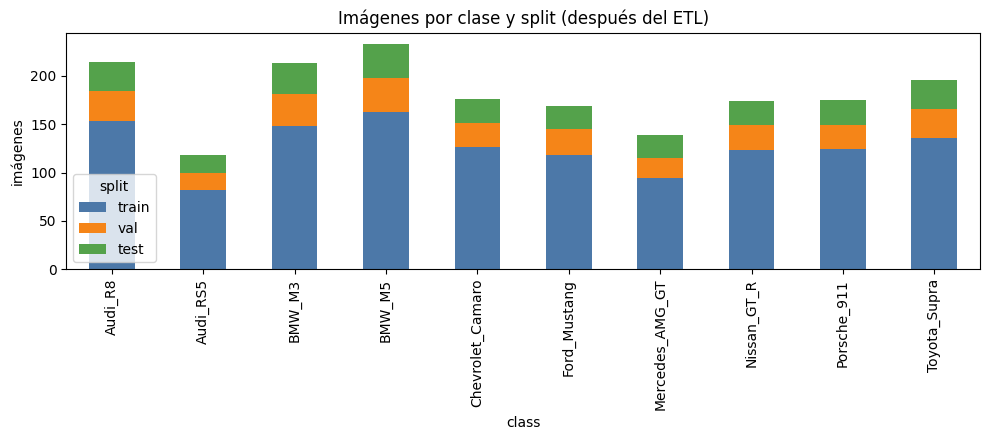

In [68]:
tab = pd.crosstab(df["class"], df["split"])[["train", "val", "test"]]
tab["total"] = tab.sum(axis=1)
display(tab)

pct = (pd.crosstab(df["class"], df["split"], normalize="index") * 100).round(1)[["train", "val", "test"]]
print("Porcentaje de cada clase que cae en cada split (debería ser ≈70 / 15 / 15):")
display(pct)

tab[["train", "val", "test"]].plot.bar(stacked=True, figsize=(10, 4.5), color=["#4C78A8", "#F58518", "#54A24B"],
                                         title="Imágenes por clase y split (después del ETL)")
plt.ylabel("imágenes"); plt.tight_layout(); plt.show()

,antes,después,eliminadas
class,,,
Audi_R8,231,214,17
Audi_RS5,124,118,6
BMW_M3,233,213,20
BMW_M5,239,233,6
Chevrolet_Camaro,225,176,49
Ford_Mustang,238,169,69
Mercedes_AMG_GT,147,139,8
Nissan_GT_R,216,174,42
Porsche_911,225,175,50


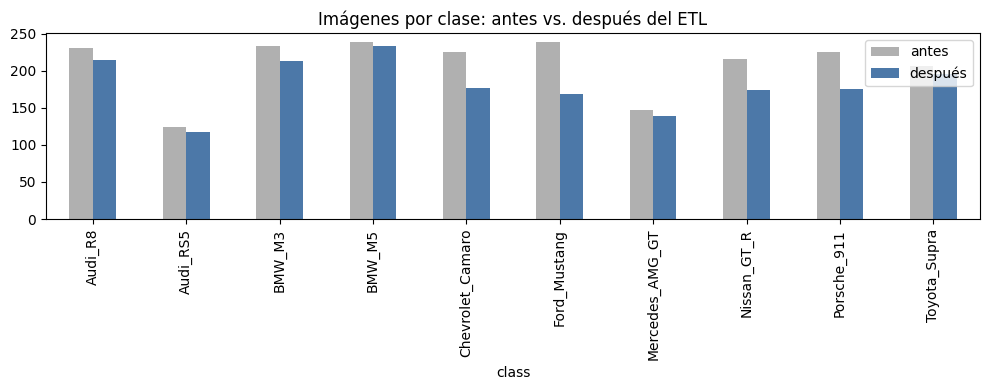

,Paso del ETL,Imágenes eliminadas
0,Archivos corruptos,0
1,No son fotos reales (fuente ≠ Flickr),1
2,Duplicados dentro de la misma clase (se conser...,4
3,Duplicados entre clases distintas (se eliminan...,12
4,"Eliminadas tras revisión visual (diagramas, LE...",260
5,TOTAL eliminadas,277


Imágenes: 2084 -> 1807  (86.7 % conservado)


In [69]:
before = inv["class"].value_counts().sort_index()
after = df["class"].value_counts().sort_index()
cmp_ = pd.DataFrame({"antes": before, "después": after})
cmp_["eliminadas"] = cmp_["antes"] - cmp_["después"]
display(cmp_)
cmp_[["antes", "después"]].plot.bar(figsize=(10, 4), color=["#B0B0B0", "#4C78A8"], title="Imágenes por clase: antes vs. después del ETL")
plt.tight_layout(); plt.show()

log = pd.DataFrame(etl_log, columns=["Paso del ETL", "Imágenes eliminadas"])
log.loc[len(log)] = ["TOTAL eliminadas", log["Imágenes eliminadas"].sum()]
display(log)
print(f"Imágenes: {n0} -> {len(df)}  ({100 * len(df) / n0:.1f} % conservado)")

In [70]:
bad_files, shapes, modes = [], Counter(), Counter()
for root, _, files_ in os.walk(PROC_DIR):
    for f in files_:
        if f.lower().endswith(".jpg"):
            try:
                with Image.open(os.path.join(root, f)) as im:
                    shapes[im.size] += 1; modes[im.mode] += 1
            except Exception as e:
                bad_files.append(f)
print("Tamaños:", dict(shapes))
print("Modos:", dict(modes))
print("Archivos con error:", len(bad_files))
assert len(bad_files) == 0 and list(shapes.keys()) == [(IMG_SIZE, IMG_SIZE)] and list(modes.keys()) == ["RGB"]

Tamaños: {(224, 224): 1807}
Modos: {'RGB': 1807}
Archivos con error: 0


val: distancia mínima a train = 10  |  imágenes con distancia <= 6: 0
test: distancia mínima a train = 10  |  imágenes con distancia <= 6: 0


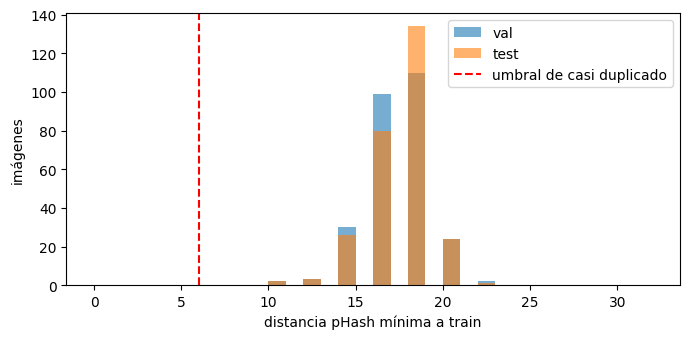

In [71]:
d = pairwise_phash_dist(df)
np.fill_diagonal(d, 99)
tr = (df["split"] == "train").values
res = {}
for s in ["val", "test"]:
    m = (df["split"] == s).values
    min_d = d[np.ix_(m, tr)].min(axis=1)
    res[s] = min_d
    print(f"{s}: distancia mínima a train = {min_d.min()}  |  imágenes con distancia <= {PHASH_GROUP_THR}: {(min_d <= PHASH_GROUP_THR).sum()}")
assert all((v > PHASH_GROUP_THR).all() for v in res.values()), "¡Hay fuga entre splits!"

plt.figure(figsize=(7, 3.5))
for s, v in res.items():
    plt.hist(v, bins=range(0, 33), alpha=0.6, label=s)
plt.axvline(PHASH_GROUP_THR, color="red", ls="--", label="umbral de casi duplicado")
plt.xlabel("distancia pHash mínima a train"); plt.ylabel("imágenes"); plt.legend(); plt.tight_layout(); plt.show()

Ninguna imagen de validación o prueba tiene un casi duplicado en entrenamiento.

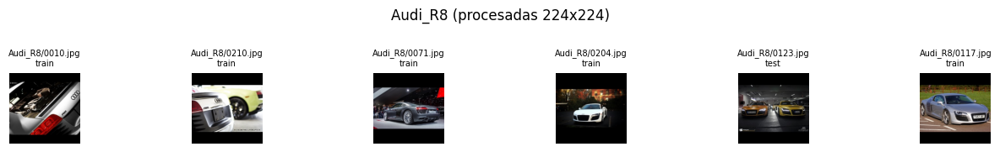

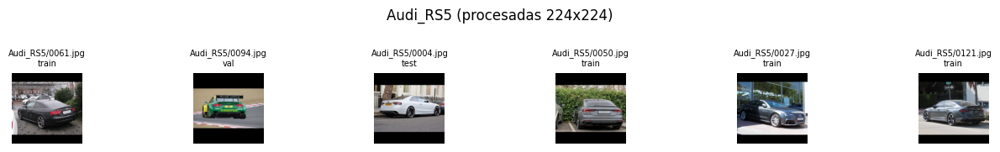

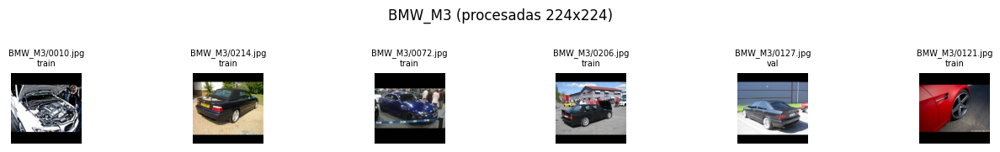

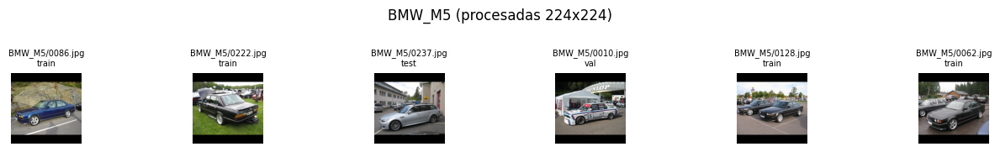

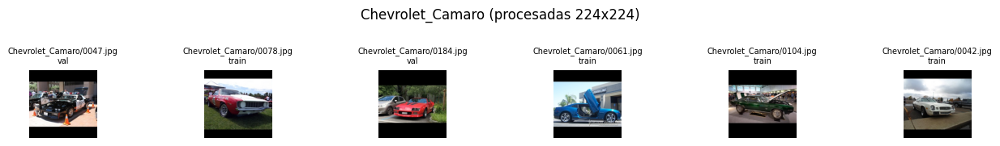

In [72]:
proc = df.copy()
proc["path"] = proc.apply(lambda r: os.path.join(PROC_DIR, r["split"], r["class"], r["filename"]), axis=1)
for c in classes[:5]:
    sample = proc[proc["class"] == c].sample(6, random_state=SEED)
    show_grid(sample, title=f"{c} (procesadas {IMG_SIZE}x{IMG_SIZE})", annotate=lambda r: r["split"])

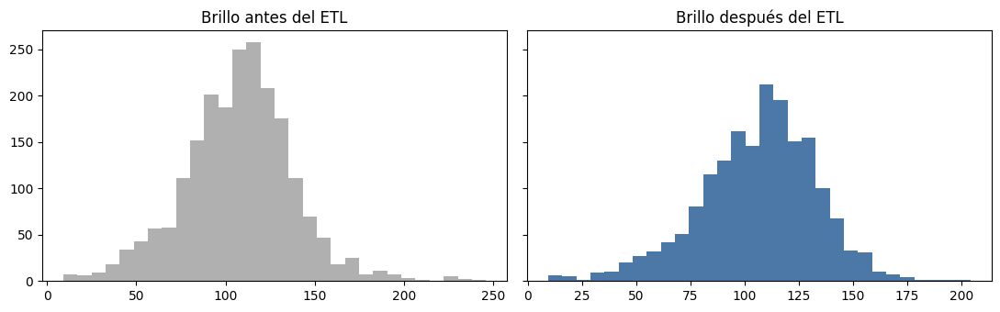

In [73]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
ax[0].hist(inv["brightness"], bins=30, color="#B0B0B0"); ax[0].set_title("Brillo antes del ETL")
ax[1].hist(df["brightness"], bins=30, color="#4C78A8");  ax[1].set_title("Brillo después del ETL")
plt.tight_layout(); plt.show()

### Exportación

In [74]:
zip_base = os.path.join(WORK_DIR, "car_dataset_processed")
zip_file = shutil.make_archive(zip_base, "zip", PROC_DIR)
print("Zip creado:", zip_file, f"({os.path.getsize(zip_file) / 1e6:.0f} MB)")

SAVE_TO_DRIVE = True
if IN_COLAB and SAVE_TO_DRIVE:
    dest = "/content/drive/MyDrive/car_dataset_processed.zip"
    shutil.copy(zip_file, dest)
    print("Copiado a Drive:", dest)

Zip creado: /content/car_dataset_processed.zip (35 MB)
Copiado a Drive: /content/drive/MyDrive/car_dataset_processed.zip


In [75]:
# Prueba rápida
try:
    import tensorflow as tf
    train_ds = tf.keras.utils.image_dataset_from_directory(
        os.path.join(PROC_DIR, "train"), image_size=(IMG_SIZE, IMG_SIZE), batch_size=32, seed=SEED, label_mode="categorical")
    val_ds = tf.keras.utils.image_dataset_from_directory(
        os.path.join(PROC_DIR, "val"), image_size=(IMG_SIZE, IMG_SIZE), batch_size=32, shuffle=False, label_mode="categorical")
    test_ds = tf.keras.utils.image_dataset_from_directory(
        os.path.join(PROC_DIR, "test"), image_size=(IMG_SIZE, IMG_SIZE), batch_size=32, shuffle=False, label_mode="categorical")
    print("Clases:", train_ds.class_names)
except ImportError:
    print("TensorFlow no está instalado en este entorno; en Colab ya viene incluido.")

Found 1267 files belonging to 10 classes.
Found 270 files belonging to 10 classes.
Found 270 files belonging to 10 classes.
Clases: ['Audi_R8', 'Audi_RS5', 'BMW_M3', 'BMW_M5', 'Chevrolet_Camaro', 'Ford_Mustang', 'Mercedes_AMG_GT', 'Nissan_GT_R', 'Porsche_911', 'Toyota_Supra']
